# A posterior, and how to check it

Neural posterior estimation on a small set of catalogue-level simulations (the published model, 10% of the
sky), its posterior for one mock, and its coverage. Needs the `sbi` extra. Runs on a laptop in about 10 min;
the published runs use 10,000 simulations and five networks.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import jax
jax.config.update("jax_enable_x64", True)
from classy_szlite.sim import survey, catalogue as ct, priors, npe, simulator

sz, le, cfg = survey.catalogue_model("published", n_tiles=41)
cfg = cfg._replace(capacity=2 ** 20)
cells = ct.survey_cells()

def simulate(theta, seed):
    key = jax.random.key(seed)
    one = jax.jit(jax.vmap(lambda i, *v: ct.data_vector(ct.simulate(
        jax.random.fold_in(key, i), simulator.THETA_FID._replace(**dict(zip(priors.NAMES, v))), cells, sz, le, cfg))))
    out = []
    for a in range(0, len(theta), 16):
        b = theta[a:a + 16]
        pad = np.concatenate([b, np.repeat(b[-1:], 16 - len(b), 0)])
        x = one(jax.numpy.arange(a, a + 16, dtype=jax.numpy.uint32), *[jax.numpy.asarray(pad[:, j]) for j in range(10)])
        out.append(np.asarray(x)[:len(b)])
    return np.concatenate(out)

t0 = time.time()
th_train = priors.draw_prior(2000, np.random.default_rng(1))
x_train = simulate(th_train, 1)
print(f"2,000 training catalogues in {time.time() - t0:.0f} s")

2,000 training catalogues in 394 s


## Training

In [2]:
post, info = npe.train(th_train, x_train, box="map", seed=11)
info

 Training neural network. Epochs trained: 5

 Training neural network. Epochs trained: 10

 Training neural network. Epochs trained: 15

 Training neural network. Epochs trained: 20

 Training neural network. Epochs trained: 25

 Training neural network. Epochs trained: 30

... (136 outputs left out)

 Training neural network. Epochs trained: 704

 Neural network successfully converged after 708 epochs.

trained on 2000 simulations in 35 s, 708 epochs


{'n_train': 2000,
 'epochs': 708,
 'seconds': 35.28309488296509,
 'sbi': '0.27.0',
 'seed': 11}

## One mock

A catalogue at the true parameters, and the posterior of the four parameters the counts constrain.

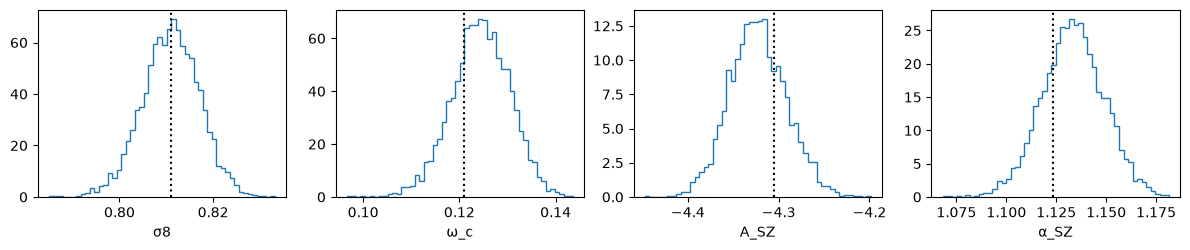

In [3]:
th_mock = priors.draws("truth", 1)
x_mock = simulate(th_mock, 2)
s = npe.sample(post, x_mock[0], 4000)
fig, ax = plt.subplots(1, 4, figsize=(12, 2.6))
for j, a in enumerate(ax):
    a.hist(s[:, j], 50, histtype="step", density=True)
    a.axvline(th_mock[0, j], color="k", ls=":")
    a.set_xlabel(priors.LABELS[j])
plt.tight_layout()

## Coverage

On 100 prior draws: the fraction whose true value lies in each central credible interval. A calibrated
posterior follows the diagonal (with 100 draws, expect deviations of about ±0.05).

7 s; bias over the prior draws: [ 0.03 -0.16  0.01 -0.04]


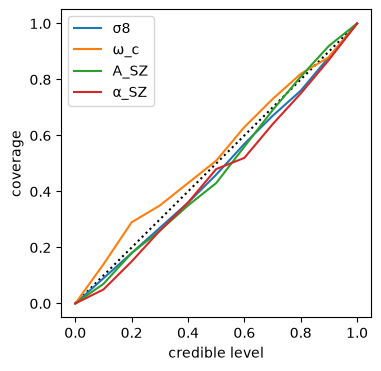

In [4]:
th_test = priors.draw_prior(100, np.random.default_rng(3))
x_test = simulate(th_test, 3)
t0 = time.time()
summ = npe.summarise(post, th_test, x_test, n_samples=1000)
cov = npe.coverage(summ)
print(f"{time.time() - t0:.0f} s; bias over the prior draws:", np.round(npe.bias(summ)["bias"][:4], 2))
plt.figure(figsize=(4, 4))
plt.plot([0, 1], [0, 1], "k:")
for j in range(4):
    plt.plot(np.r_[0, npe.LEVELS, 1], np.r_[0, cov[:, j], 1], label=priors.LABELS[j])
plt.xlabel("credible level"); plt.ylabel("coverage"); plt.legend()